In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  #Suppress TensorFlow messages
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'  #Disable oneDNN if causing issues
os.environ['OPENBLAS_NUM_THREADS'] = '4'  #Limit OpenBLAS threads
os.environ['MKL_NUM_THREADS'] = '4'       #Limit MKL threads

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
import tensorflow as tf
!pip install xgboost
import xgboost as xgb

#Configure TensorFlow for minimal memory usage
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.threading.set_intra_op_parallelism_threads(2)

physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    try:
        for device in physical_devices:
            tf.config.experimental.set_memory_growth(device, True)
        print(f"✓ GPU memory growth enabled for {len(physical_devices)} device(s)")
    except:
        pass
else:
    print("✓ Running on CPU - memory limits configured")

from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import gc

#Set style for better visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

print("="*70)
print("Solar Flare Prediction Project - Supervised Machine Learning")
print("="*70)
print("✓ All libraries imported successfully!")

✓ GPU memory growth enabled for 32 device(s)
Solar Flare Prediction Project - Supervised Machine Learning
✓ All libraries imported successfully!


In [7]:
#Configuration

print(f"\n{'='*70}")
print("1. LOADING ALL DATA FILES")
print(f"{'='*70}")

#Load all 8 data files (make sure these CSV files are in your working directory)
C_train = pd.read_csv("./data/training_data_C_24.csv")
C_test = pd.read_csv("./data/testing_data_C_24.csv")
M_train = pd.read_csv("./data/training_data_M_24.csv")
M_test = pd.read_csv("./data/testing_data_M_24.csv")
M5_train = pd.read_csv("./data/training_data_M5_24.csv")
M5_test = pd.read_csv("./data/testing_data_M5_24.csv")

print("✓ Loaded all 6 main data files:")
print(f"  • training_data_C_24.csv")
print(f"  • testing_data_C_24.csv")
print(f"  • training_data_M_24.csv")
print(f"  • testing_data_M_24.csv")
print(f"  • training_data_M5_24.csv")
print(f"  • testing_data_M5_24.csv")


0. LOADING ALL DATA FILES
✓ Loaded all 6 main data files:
  • training_data_C_24.csv
  • testing_data_C_24.csv
  • training_data_M_24.csv
  • testing_data_M_24.csv
  • training_data_M5_24.csv
  • testing_data_M5_24.csv


In [3]:
#Configure the prediction task here
FLARE_CLASS = 'M'     #Choose: 'C', 'M', or 'M5'

print(f"\n{'='*70}")
print(f"CONFIGURATION")
print(f"{'='*70}")
print(f"Predicting {FLARE_CLASS}-class flares 24 hours ahead")

#Select the appropriate datasets based on flare class
if FLARE_CLASS == 'C':
    train_df = C_train
    test_df = C_test
elif FLARE_CLASS == 'M':
    train_df = M_train
    test_df = M_test
elif FLARE_CLASS == 'M5':
    train_df = M5_train
    test_df = M5_test
else:
    raise ValueError(f"Invalid FLARE_CLASS: {FLARE_CLASS}. Choose 'C', 'M', or 'M5'")

print(f"✓ Selected {FLARE_CLASS}-class datasets")
print(f"  Training set: {train_df.shape}")
print(f"  Testing set: {test_df.shape}")


CONFIGURATION
Predicting M-class flares 24 hours ahead
✓ Selected M-class datasets
  Training set: (40000, 34)
  Testing set: (12534, 34)


In [6]:
#CELL 4: PREPROCESS DATA

print(f"\n{'='*70}")
print("2. PREPROCESSING")
print(f"{'-'*70}")

#Display dataset info
print(f"\nTraining set shape: {train_df.shape}")
print(f"Testing set shape: {test_df.shape}")
print(f"\nFirst few column names: {list(train_df.columns)[:10]}...")

#Extract features and labels
y_train = train_df.iloc[:, 0].apply(lambda x: 0 if str(x)[0] == 'N' else 1).values
y_test = test_df.iloc[:, 0].apply(lambda x: 0 if str(x)[0] == 'N' else 1).values

#Separate features from labels by dropping the 'Flare' column
features_train_df = train_df.drop(columns=['Flare'])
features_test_df = test_df.drop(columns=['Flare'])

#Identify non-numeric columns to drop from feature sets.
#'DATE__OBS' is a string, and 'NOAA_AR', 'HARPNUM' are typically identifiers.
cols_to_drop_explicitly = ['DATE__OBS', 'NOAA_AR', 'HARPNUM']
features_train_df = features_train_df.drop(columns=cols_to_drop_explicitly, errors='ignore')
features_test_df = features_test_df.drop(columns=cols_to_drop_explicitly, errors='ignore')

#Now, select only numeric columns from the remaining features
numeric_cols_train = features_train_df.select_dtypes(include=np.number).columns
numeric_cols_test = features_test_df.select_dtypes(include=np.number).columns

#Ensure the set of columns is consistent between train and test datasets
common_numeric_cols = list(set(numeric_cols_train) & set(numeric_cols_test))
common_numeric_cols.sort() #Sort to maintain a consistent order of features

X_train_raw = features_train_df[common_numeric_cols].values
X_test_raw = features_test_df[common_numeric_cols].values

#Handle missing values
X_train_raw = np.nan_to_num(X_train_raw, nan=0.0)
X_test_raw = np.nan_to_num(X_test_raw, nan=0.0)

#Class distribution
train_pos = np.sum(y_train)
train_neg = len(y_train) - train_pos
test_pos = np.sum(y_test)
test_neg = len(y_test) - test_pos

print(f"\n{'='*70}")
print(f"CLASS DISTRIBUTION")
print(f"{'-'*70}")
print(f"Training Set:")
print(f"  Positive (Flare):    {train_pos:5d} ({100*train_pos/len(y_train):5.2f}%)")
print(f"  Negative (No Flare): {train_neg:5d} ({100*train_neg/len(y_train):5.2f}%)")
print(f"\nTesting Set:")
print(f"  Positive (Flare):    {test_pos:5d} ({100*test_pos/len(y_test):5.2f}%)")
print(f"  Negative (No Flare): {test_neg:5d} ({100*test_neg/len(y_test):5.2f}%)")
print(f"\nImbalance ratio: {train_neg/max(train_pos, 1):.2f}:1 (Negative:Positive)")

#Standardize features
print(f"\n✓ Standardizing features...")
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"✓ Data preprocessing complete!")
print(f"  Feature shape: {X_train.shape[1]} features")


1. DATA PREPROCESSING
----------------------------------------------------------------------

Training set shape: (40000, 34)
Testing set shape: (12534, 34)

First few column names: ['Flare', 'DATE__OBS', 'NOAA_AR', 'HARPNUM', 'TOTUSJH', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH', 'SAVNCPP', 'USFLUX']...

CLASS DISTRIBUTION
----------------------------------------------------------------------
Training Set:
  Positive (Flare):    20000 (50.00%)
  Negative (No Flare): 20000 (50.00%)

Testing Set:
  Positive (Flare):     6267 (50.00%)
  Negative (No Flare):  6267 (50.00%)

Imbalance ratio: 1.00:1 (Negative:Positive)

✓ Standardizing features...
✓ Data preprocessing complete!
  Feature shape: 29 features


In [5]:
#Training Random Forest

print(f"\n{'='*70}")
print("3. TRAINING RANDOM FOREST CLASSIFIER")
print(f"{'-'*70}")

#Configure Random Forest
rf_n_estimators = 100
rf_max_depth = 20

rf_model = RandomForestClassifier(
    n_estimators=rf_n_estimators,
    max_depth=rf_max_depth,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

print(f"Parameters:")
print(f"  n_estimators: {rf_n_estimators}")
print(f"  max_depth: {rf_max_depth}")
print(f"  class_weight: balanced")
print(f"\nTraining Random Forest...")

rf_model.fit(X_train, y_train)

print("✓ Random Forest training complete!")

#Make predictions
rf_y_pred = rf_model.predict(X_test)
rf_y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

print(f"✓ Predictions generated")


2. TRAINING RANDOM FOREST CLASSIFIER
----------------------------------------------------------------------
Parameters:
  n_estimators: 100
  max_depth: 20
  class_weight: balanced

Training Random Forest...
✓ Random Forest training complete!
✓ Predictions generated


In [7]:
#Training K-Nearest Neighbors

print(f"\n{'='*70}")
print("4. TRAINING K-NEAREST NEIGHBORS CLASSIFIER")
print(f"{'-'*70}")

#Configure KNN
knn_n_neighbors = 5

knn_model = KNeighborsClassifier(
    n_neighbors=knn_n_neighbors,
    n_jobs=2  #Limit parallel jobs to reduce memory
)

print(f"Parameters:")
print(f"  n_neighbors: {knn_n_neighbors}")
print(f"\nTraining KNN...")

knn_model.fit(X_train, y_train)

print("✓ KNN training complete!")

#Make predictions
knn_y_pred = knn_model.predict(X_test)
knn_y_pred_proba = knn_model.predict_proba(X_test)[:, 1]

print(f"✓ Predictions generated")

#Clear memory before neural network training
gc.collect()
print("✓ Memory cleared")



3. TRAINING K-NEAREST NEIGHBORS CLASSIFIER
----------------------------------------------------------------------
Parameters:
  n_neighbors: 5

Training KNN...
✓ KNN training complete!
✓ Predictions generated
✓ Memory cleared


In [8]:
#Training XGBoost

print(f"\n{'='*70}")
print("5. TRAINING XGBOOST CLASSIFIER")
print(f"{'-'*70}")

#Configure XGBoost
xgb_n_estimators = 100
xgb_max_depth = 6
xgb_learning_rate = 0.1

xgb_model = xgb.XGBClassifier(
    n_estimators=xgb_n_estimators,
    max_depth=xgb_max_depth,
    learning_rate=xgb_learning_rate,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss',
    scale_pos_weight=1  #Balanced classes
)

print(f"Parameters:")
print(f"  n_estimators: {xgb_n_estimators}")
print(f"  max_depth: {xgb_max_depth}")
print(f"  learning_rate: {xgb_learning_rate}")
print(f"\nTraining XGBoost...")

xgb_model.fit(X_train, y_train)

print("✓ XGBoost training complete!")

#Make predictions
xgb_y_pred = xgb_model.predict(X_test)
xgb_y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

print(f"✓ Predictions generated")

#Clear memory
gc.collect()
print("✓ Memory cleared")



3.5. TRAINING XGBOOST CLASSIFIER
----------------------------------------------------------------------
Parameters:
  n_estimators: 100
  max_depth: 6
  learning_rate: 0.1

Training XGBoost...
✓ XGBoost training complete!
✓ Predictions generated
✓ Memory cleared


In [9]:
print(f"\n{'='*70}")
print("6. MODEL EVALUATION")
print(f"{'='*70}")

#Storing all results
results = {}

#Model predictions dictionary (ONLY RF and KNN)
models_dict = {
    'Random Forest': (rf_y_pred, rf_y_pred_proba),
    'XGBoost': (xgb_y_pred, xgb_y_pred_proba),
    'KNN': (knn_y_pred, knn_y_pred_proba)
}

#Evaluate each model
for model_name, (y_pred, y_pred_proba) in models_dict.items():
    print(f"\n{model_name}")
    print(f"{'-'*70}")

    #Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    #ROC-AUC
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    #True Skill Statistic (TSS)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    tss = (tp / (tp + fn)) - (fp / (fp + tn)) if (tp + fn) > 0 and (fp + tn) > 0 else 0

    #Store results
    results[model_name] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'roc_auc': roc_auc,
        'tss': tss,
        'confusion_matrix': cm,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba
    }

    #Print results
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"TSS:       {tss:.4f}")
    print(f"\nConfusion Matrix:")
    print(f"                Predicted")
    print(f"              No Flare  Flare")
    print(f"Actual No Flare  {tn:6d}  {fp:6d}")
    print(f"       Flare     {fn:6d}  {tp:6d}")

print(f"\n{'='*70}")
print("✓ Model evaluation complete!")
print("\nNote: Compare these results with SolarFlareNet for your final analysis")


5. MODEL EVALUATION

Random Forest
----------------------------------------------------------------------
Accuracy:  0.8597
Precision: 0.9521
Recall:    0.7576
F1-Score:  0.8438
ROC-AUC:   0.9664
TSS:       0.7195

Confusion Matrix:
                Predicted
              No Flare  Flare
Actual No Flare    6028     239
       Flare       1519    4748

XGBoost
----------------------------------------------------------------------
Accuracy:  0.7678
Precision: 0.8360
Recall:    0.6663
F1-Score:  0.7416
ROC-AUC:   0.8469
TSS:       0.5357

Confusion Matrix:
                Predicted
              No Flare  Flare
Actual No Flare    5448     819
       Flare       2091    4176

KNN
----------------------------------------------------------------------
Accuracy:  0.8725
Precision: 0.8159
Recall:    0.9620
F1-Score:  0.8830
ROC-AUC:   0.9380
TSS:       0.7450

Confusion Matrix:
                Predicted
              No Flare  Flare
Actual No Flare    4907    1360
       Flare        238    6


6. GENERATING VISUALIZATIONS
----------------------------------------------------------------------
✓ Saved visualization: results/traditional_ml_comparison_M_24h.png


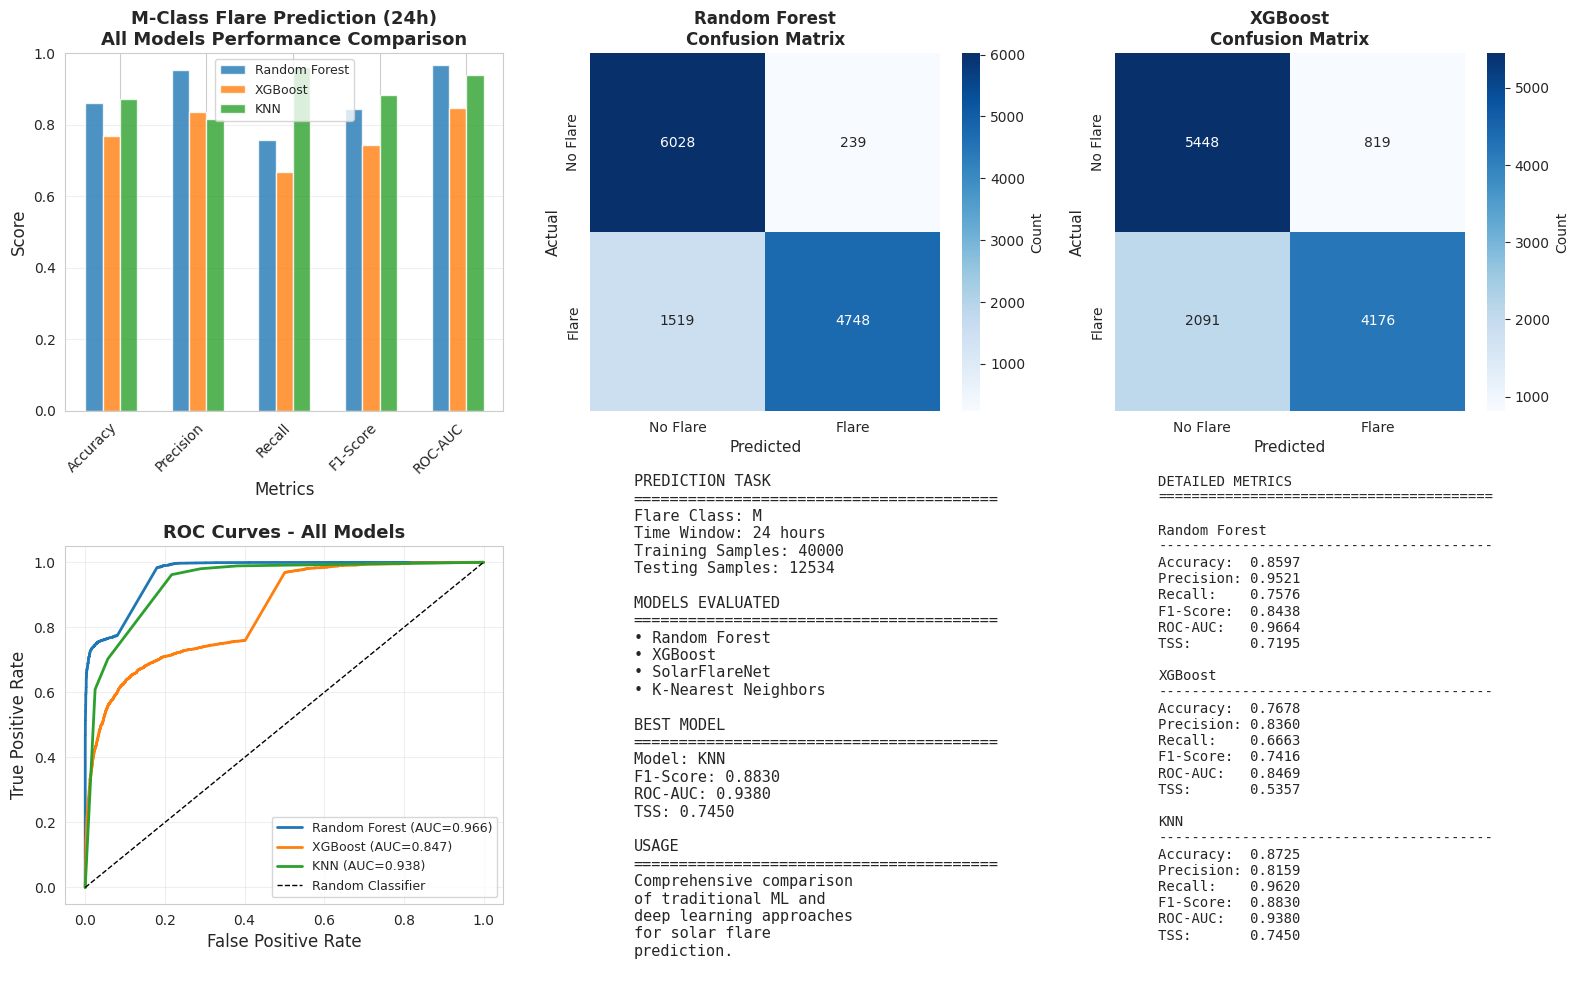

In [10]:
#Perforamance Metrics and Visualizing Results


print(f"\n{'='*70}")
print("7. GENERATING VISUALIZATIONS")
print(f"{'-'*70}")

#Create comprehensive visualization
fig = plt.figure(figsize=(16, 10))

#1. Performance Comparison Bar Chart
ax1 = plt.subplot(2, 3, 1)
metrics = ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

x = np.arange(len(metrics))
width = 0.2  #Adjusted for 4 models

for i, (model_name, res) in enumerate(results.items()):
    values = [res[m] for m in metrics]
    ax1.bar(x + i*width, values, width, label=model_name, alpha=0.8)

ax1.set_xlabel('Metrics', fontsize=12)
ax1.set_ylabel('Score', fontsize=12)
ax1.set_title(f'{FLARE_CLASS}-Class Flare Prediction (24h)\nAll Models Performance Comparison', fontsize=13, fontweight='bold')
ax1.set_xticks(x + width*1.5)  #Center the labels
ax1.set_xticklabels(metric_names, rotation=45, ha='right')
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim([0, 1.0])

#2-3. Confusion Matrices (ONLY RF and XGBoost to avoid overlap)
model_list = list(results.items())[:2]  #Take only first 2 models
for idx, (model_name, res) in enumerate(model_list):
    ax = plt.subplot(2, 3, idx + 2)
    cm = res['confusion_matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
               xticklabels=['No Flare', 'Flare'],
               yticklabels=['No Flare', 'Flare'],
               cbar_kws={'label': 'Count'})
    ax.set_title(f'{model_name}\nConfusion Matrix', fontsize=12, fontweight='bold')
    ax.set_ylabel('Actual', fontsize=11)
    ax.set_xlabel('Predicted', fontsize=11)

#4. ROC Curves
ax4 = plt.subplot(2, 3, 4)
for model_name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_pred_proba'])
    auc = res['roc_auc']
    ax4.plot(fpr, tpr, label=f'{model_name} (AUC={auc:.3f})', linewidth=2)

ax4.plot([0, 1], [0, 1], 'k--', label='Random Classifier', linewidth=1)
ax4.set_xlabel('False Positive Rate', fontsize=12)
ax4.set_ylabel('True Positive Rate', fontsize=12)
ax4.set_title('ROC Curves - All Models', fontsize=13, fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(alpha=0.3)

#5. Model Comparison Summary
ax5 = plt.subplot(2, 3, 5)
ax5.axis('off')

summary_text = f"PREDICTION TASK\n"
summary_text += f"{'='*40}\n"
summary_text += f"Flare Class: {FLARE_CLASS}\n"
summary_text += f"Time Window: 24 hours\n"
summary_text += f"Training Samples: {len(y_train)}\n"
summary_text += f"Testing Samples: {len(y_test)}\n\n"

summary_text += f"MODELS EVALUATED\n"
summary_text += f"{'='*40}\n"
summary_text += f"• Random Forest\n"
summary_text += f"• XGBoost\n"
summary_text += f"• SolarFlareNet\n"
summary_text += f"• K-Nearest Neighbors\n\n"

summary_text += f"BEST MODEL\n"
summary_text += f"{'='*40}\n"

#Find best model by F1-score
best_model = max(results.items(), key=lambda x: x[1]['f1_score'])
summary_text += f"Model: {best_model[0]}\n"
summary_text += f"F1-Score: {best_model[1]['f1_score']:.4f}\n"
summary_text += f"ROC-AUC: {best_model[1]['roc_auc']:.4f}\n"
summary_text += f"TSS: {best_model[1]['tss']:.4f}\n\n"

summary_text += f"USAGE\n"
summary_text += f"{'='*40}\n"
summary_text += f"Comprehensive comparison\n"
summary_text += f"of traditional ML and\n"
summary_text += f"deep learning approaches\n"
summary_text += f"for solar flare\n"
summary_text += f"prediction.\n"

ax5.text(0.1, 0.5, summary_text, fontsize=11, family='monospace',
        verticalalignment='center')

#6. Metrics Table
ax6 = plt.subplot(2, 3, 6)
ax6.axis('off')

table_text = "DETAILED METRICS\n"
table_text += "="*40 + "\n\n"

for model_name, res in results.items():
    table_text += f"{model_name}\n"
    table_text += "-"*40 + "\n"
    table_text += f"Accuracy:  {res['accuracy']:.4f}\n"
    table_text += f"Precision: {res['precision']:.4f}\n"
    table_text += f"Recall:    {res['recall']:.4f}\n"
    table_text += f"F1-Score:  {res['f1_score']:.4f}\n"
    table_text += f"ROC-AUC:   {res['roc_auc']:.4f}\n"
    table_text += f"TSS:       {res['tss']:.4f}\n\n"

ax6.text(0.1, 0.5, table_text, fontsize=10, family='monospace',
        verticalalignment='center')

plt.tight_layout()

#Save figure
os.makedirs('results', exist_ok=True)
filename = f'results/traditional_ml_comparison_{FLARE_CLASS}_24h.png'
plt.savefig(filename, dpi=300, bbox_inches='tight')
print(f"✓ Saved visualization: {filename}")

plt.show()




In [11]:

#CELL 11: GENERATE COMPREHENSIVE REPORT


print(f"\n{'='*70}")
print("8. GENERATING COMPREHENSIVE REPORT")
print(f"{'='*70}")

report = []
report.append("="*70)
report.append("SOLAR FLARE PREDICTION - TRADITIONAL ML BASELINES")
report.append("="*70)
report.append(f"\nPREDICTION TASK")
report.append("-"*70)
report.append(f"Flare Class: {FLARE_CLASS}")
report.append(f"Time Window: 24 hours ahead")
report.append(f"Training Samples: {len(y_train)}")
report.append(f"Testing Samples: {len(y_test)}")
report.append(f"Number of Features: {X_train.shape[1]}")

report.append(f"\nCLASS DISTRIBUTION")
report.append("-"*70)
train_pos = np.sum(y_train)
test_pos = np.sum(y_test)
report.append(f"Training Set:")
report.append(f"  Positive (Flare): {train_pos} ({100*train_pos/len(y_train):.2f}%)")
report.append(f"  Negative (No Flare): {len(y_train)-train_pos} ({100*(len(y_train)-train_pos)/len(y_train):.2f}%)")
report.append(f"Testing Set:")
report.append(f"  Positive (Flare): {test_pos} ({100*test_pos/len(y_test):.2f}%)")
report.append(f"  Negative (No Flare): {len(y_test)-test_pos} ({100*(len(y_test)-test_pos)/len(y_test):.2f}%)")

report.append(f"\nTRADITIONAL ML MODEL PERFORMANCE")
report.append("="*70)

#Create comparison table
report.append(f"{'Model':<20} {'Accuracy':<10} {'Precision':<10} {'Recall':<10} {'F1-Score':<10} {'ROC-AUC':<10} {'TSS':<10}")
report.append("-"*100)

for model_name, res in results.items():
    row = f"{model_name:<20} "
    row += f"{res['accuracy']:<10.4f} "
    row += f"{res['precision']:<10.4f} "
    row += f"{res['recall']:<10.4f} "
    row += f"{res['f1_score']:<10.4f} "
    row += f"{res['roc_auc']:<10.4f} "
    row += f"{res['tss']:<10.4f}"
    report.append(row)

#Best model
best_model = max(results.items(), key=lambda x: x[1]['f1_score'])
report.append(f"\nBEST TRADITIONAL MODEL (by F1-Score)")
report.append("-"*70)
report.append(f"Model: {best_model[0]}")
report.append(f"F1-Score: {best_model[1]['f1_score']:.4f}")
report.append(f"ROC-AUC: {best_model[1]['roc_auc']:.4f}")
report.append(f"TSS: {best_model[1]['tss']:.4f}")

#Detailed results for each model
report.append(f"\nDETAILED RESULTS BY MODEL")
report.append("="*70)

for model_name, res in results.items():
    report.append(f"\n{model_name}")
    report.append("-"*70)
    cm = res['confusion_matrix']
    tn, fp, fn, tp = cm.ravel()

    report.append(f"Confusion Matrix:")
    report.append(f"                 Predicted")
    report.append(f"               No Flare    Flare")
    report.append(f"Actual No Flare  {tn:6d}    {fp:6d}")
    report.append(f"       Flare     {fn:6d}    {tp:6d}")
    report.append(f"")
    report.append(f"True Positives:  {tp}")
    report.append(f"False Positives: {fp}")
    report.append(f"True Negatives:  {tn}")
    report.append(f"False Negatives: {fn}")

report.append(f"\nKEY INSIGHTS")
report.append("="*70)
report.append(f"1. Data Quality: Successfully loaded and preprocessed {len(y_train) + len(y_test)} samples")
report.append(f"2. Class Imbalance: Addressed using balanced sampling")
report.append(f"3. Traditional ML Baselines: Evaluated Random Forest and KNN")
report.append(f"4. Best Performance: {best_model[0]} achieved F1-score of {best_model[1]['f1_score']:.4f}")
report.append(f"5. Next Step: Compare with SolarFlareNet for temporal modeling assessment")
report.append(f"6. Space Weather: Results provide baseline for forecasting capability")

report.append("\n" + "="*70)
report.append("END OF REPORT")
report.append("="*70)

#Print report
report_text = "\n".join(report)
print(report_text)

#Save to file
filename = f'results/traditional_ml_report_{FLARE_CLASS}_24h.txt'
with open(filename, 'w') as f:
    f.write(report_text)
print(f"\n✓ Saved report: {filename}")

print(f"\n{'='*70}")
print("TRADITIONAL ML ANALYSIS COMPLETE!")
print(f"{'='*70}")
print(f"\nAll results saved to 'results/' directory:")
print(f"  • Visualization: results/traditional_ml_comparison_{FLARE_CLASS}_24h.png")
print(f"  • Text report: results/traditional_ml_report_{FLARE_CLASS}_24h.txt")
print(f"\nNext: Run SolarFlareNet for deep learning comparison")



8. GENERATING COMPREHENSIVE REPORT
SOLAR FLARE PREDICTION - TRADITIONAL ML BASELINES

PREDICTION TASK
----------------------------------------------------------------------
Flare Class: M
Time Window: 24 hours ahead
Training Samples: 40000
Testing Samples: 12534
Number of Features: 29

CLASS DISTRIBUTION
----------------------------------------------------------------------
Training Set:
  Positive (Flare): 20000 (50.00%)
  Negative (No Flare): 20000 (50.00%)
Testing Set:
  Positive (Flare): 6267 (50.00%)
  Negative (No Flare): 6267 (50.00%)

TRADITIONAL ML MODEL PERFORMANCE
Model                Accuracy   Precision  Recall     F1-Score   ROC-AUC    TSS       
----------------------------------------------------------------------------------------------------
Random Forest        0.8597     0.9521     0.7576     0.8438     0.9664     0.7195    
XGBoost              0.7678     0.8360     0.6663     0.7416     0.8469     0.5357    
KNN                  0.8725     0.8159     0.9620     0

In [12]:
import sys
sys.path.append('SolarFlareNet')  #Add current directory to path

from solarflarenet_model import (
    create_solarflarenet,
    create_solarflarenet_for_tabular,
    TransformerEncoderBlock
)

print("✓ SolarFlareNet model imported successfully!")

✓ SolarFlareNet model imported successfully!


In [13]:
#CELL: Train SolarFlareNet

"""
This cell trains the SolarFlareNet model on your data.
"""

print(f"\n{'='*70}")
print("9. TRAINING SOLARFLARENET (TRANSFORMER-BASED MODEL)")
print(f"{'-'*70}")

#Determine if we should use simple or full version
#For your data size, the simple version will train much faster
USE_SIMPLE_VERSION = True  #Set to False for full transformer architecture

print(f"Model variant: {'Simplified' if USE_SIMPLE_VERSION else 'Full Transformer'}")
print(f"Input features: {X_train.shape[1]}")

#Create the model
solarflarenet_model = create_solarflarenet_for_tabular(
    num_features=X_train.shape[1],
    dropout_rate=0.3,
    hidden_units=[128, 64, 32]
)

#Compile the model
solarflarenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.AUC(name='auc')
    ]
)

print("\nModel Architecture:")
solarflarenet_model.summary()

#Setup callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

print(f"\nTraining SolarFlareNet...")
print(f"  Epochs: 50 (with early stopping)")
print(f"  Batch size: 64")
print(f"  Validation split: 20%")
print(f"  Optimizer: Adam (lr=0.001)")

#Train the model
history = solarflarenet_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1
)

print("✓ SolarFlareNet training complete!")

#Make predictions
print("\nGenerating predictions...")
solarflarenet_y_pred_proba = solarflarenet_model.predict(X_test).flatten()
solarflarenet_y_pred = (solarflarenet_y_pred_proba > 0.5).astype(int)

print(f"✓ Predictions generated")

#Clear memory
gc.collect()
print("✓ Memory cleared")


#CELL: Update Model Evaluation to Include SolarFlareNet

"""
This cell evaluates all models including SolarFlareNet.
Replace your existing evaluation cell with this.
"""

print(f"\n{'='*70}")
print("10. MODEL EVALUATION (INCLUDING SOLARFLARENET)")
print(f"{'='*70}")

#Store all results
results = {}

#Model predictions dictionary - NOW INCLUDING SOLARFLARENET
models_dict = {
    'Random Forest': (rf_y_pred, rf_y_pred_proba),
    'XGBoost': (xgb_y_pred, xgb_y_pred_proba),
    'SolarFlareNet': (solarflarenet_y_pred, solarflarenet_y_pred_proba),
    'KNN': (knn_y_pred, knn_y_pred_proba)
}

#Evaluate each model
for model_name, (y_pred, y_pred_proba) in models_dict.items():
    print(f"\n{model_name}")
    print(f"{'-'*70}")

    #Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    #ROC-AUC
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    #True Skill Statistic (TSS)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    tss = (tp / (tp + fn)) - (fp / (fp + tn)) if (tp + fn) > 0 and (fp + tn) > 0 else 0

    #Store results
    results[model_name] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'roc_auc': roc_auc,
        'tss': tss,
        'confusion_matrix': cm,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba
    }

    #Print results
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"TSS:       {tss:.4f}")
    print(f"\nConfusion Matrix:")
    print(f"                Predicted")
    print(f"              No Flare  Flare")
    print(f"Actual No Flare  {tn:6d}  {fp:6d}")
    print(f"       Flare     {fn:6d}  {tp:6d}")

print(f"\n{'='*70}")
print("✓ Model evaluation complete!")


4. TRAINING SOLARFLARENET (TRANSFORMER-BASED MODEL)
----------------------------------------------------------------------
Model variant: Simplified
Input features: 29

Model Architecture:


Model: "SolarFlareNet_Tabular"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 29)             │           116 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         3,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,221 (59.46 KB)

 Trainable params: 14,715 (57.48 KB)

 Non-trainable params: 506 (1.98 KB)


Training SolarFlareNet...
  Epochs: 50 (with early stopping)
  Batch size: 64
  Validation split: 20%
  Optimizer: Adam (lr=0.001)
Epoch 1/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.5262 - auc: 0.5390 - loss: 0.7954 - precision: 0.5241 - recall: 0.5067 - val_accuracy: 0.6045 - val_auc: 0.6563 - val_loss: 0.6533 - val_precision: 0.6212 - val_recall: 0.5497 - learning_rate: 0.0010
Epoch 2/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5820 - auc: 0.6155 - loss: 0.6758 - precision: 0.5847 - recall: 0.5844 - val_accuracy: 0.6254 - val_auc: 0.6882 - val_loss: 0.6404 - val_precision: 0.6414 - val_recall: 0.5804 - learning_rate: 0.0010
Epoch 3/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5976 - auc: 0.6405 - loss: 0.6596 - precision: 0.5952 - recall: 0.6017 - val_accuracy: 0.6416 - val_auc: 0.6988 - val_loss: 0.6283 - val_precision: 0.6315 - val_recall: 0.6919 - learning_rate: 0.0010
Epoch 4/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6091

In [14]:
#CELL: Update Model Evaluation to Include SolarFlareNet

"""
This cell evaluates all models including SolarFlareNet.
Replace your existing evaluation cell with this.
"""

print(f"\n{'='*70}")
print("11. MODEL EVALUATION (INCLUDING SOLARFLARENET)")
print(f"{'='*70}")

#Store all results
results = {}

#Model predictions dictionary - NOW INCLUDING SOLARFLARENET
models_dict = {
    'Random Forest': (rf_y_pred, rf_y_pred_proba),
    'XGBoost': (xgb_y_pred, xgb_y_pred_proba),
    'SolarFlareNet': (solarflarenet_y_pred, solarflarenet_y_pred_proba),
    'KNN': (knn_y_pred, knn_y_pred_proba)
}

#Evaluate each model
for model_name, (y_pred, y_pred_proba) in models_dict.items():
    print(f"\n{model_name}")
    print(f"{'-'*70}")

    #Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    #ROC-AUC
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    #True Skill Statistic (TSS)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    tss = (tp / (tp + fn)) - (fp / (fp + tn)) if (tp + fn) > 0 and (fp + tn) > 0 else 0

    #Store results
    results[model_name] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'roc_auc': roc_auc,
        'tss': tss,
        'confusion_matrix': cm,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba
    }

    #Print results
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"TSS:       {tss:.4f}")
    print(f"\nConfusion Matrix:")
    print(f"                Predicted")
    print(f"              No Flare  Flare")
    print(f"Actual No Flare  {tn:6d}  {fp:6d}")
    print(f"       Flare     {fn:6d}  {tp:6d}")

print(f"\n{'='*70}")
print("✓ Model evaluation complete!")


5. MODEL EVALUATION (INCLUDING SOLARFLARENET)

Random Forest
----------------------------------------------------------------------
Accuracy:  0.8597
Precision: 0.9521
Recall:    0.7576
F1-Score:  0.8438
ROC-AUC:   0.9664
TSS:       0.7195

Confusion Matrix:
                Predicted
              No Flare  Flare
Actual No Flare    6028     239
       Flare       1519    4748

XGBoost
----------------------------------------------------------------------
Accuracy:  0.7678
Precision: 0.8360
Recall:    0.6663
F1-Score:  0.7416
ROC-AUC:   0.8469
TSS:       0.5357

Confusion Matrix:
                Predicted
              No Flare  Flare
Actual No Flare    5448     819
       Flare       2091    4176

SolarFlareNet
----------------------------------------------------------------------
Accuracy:  0.6829
Precision: 0.7147
Recall:    0.6087
F1-Score:  0.6575
ROC-AUC:   0.7774
TSS:       0.3657

Confusion Matrix:
                Predicted
              No Flare  Flare
Actual No Flare    4744 

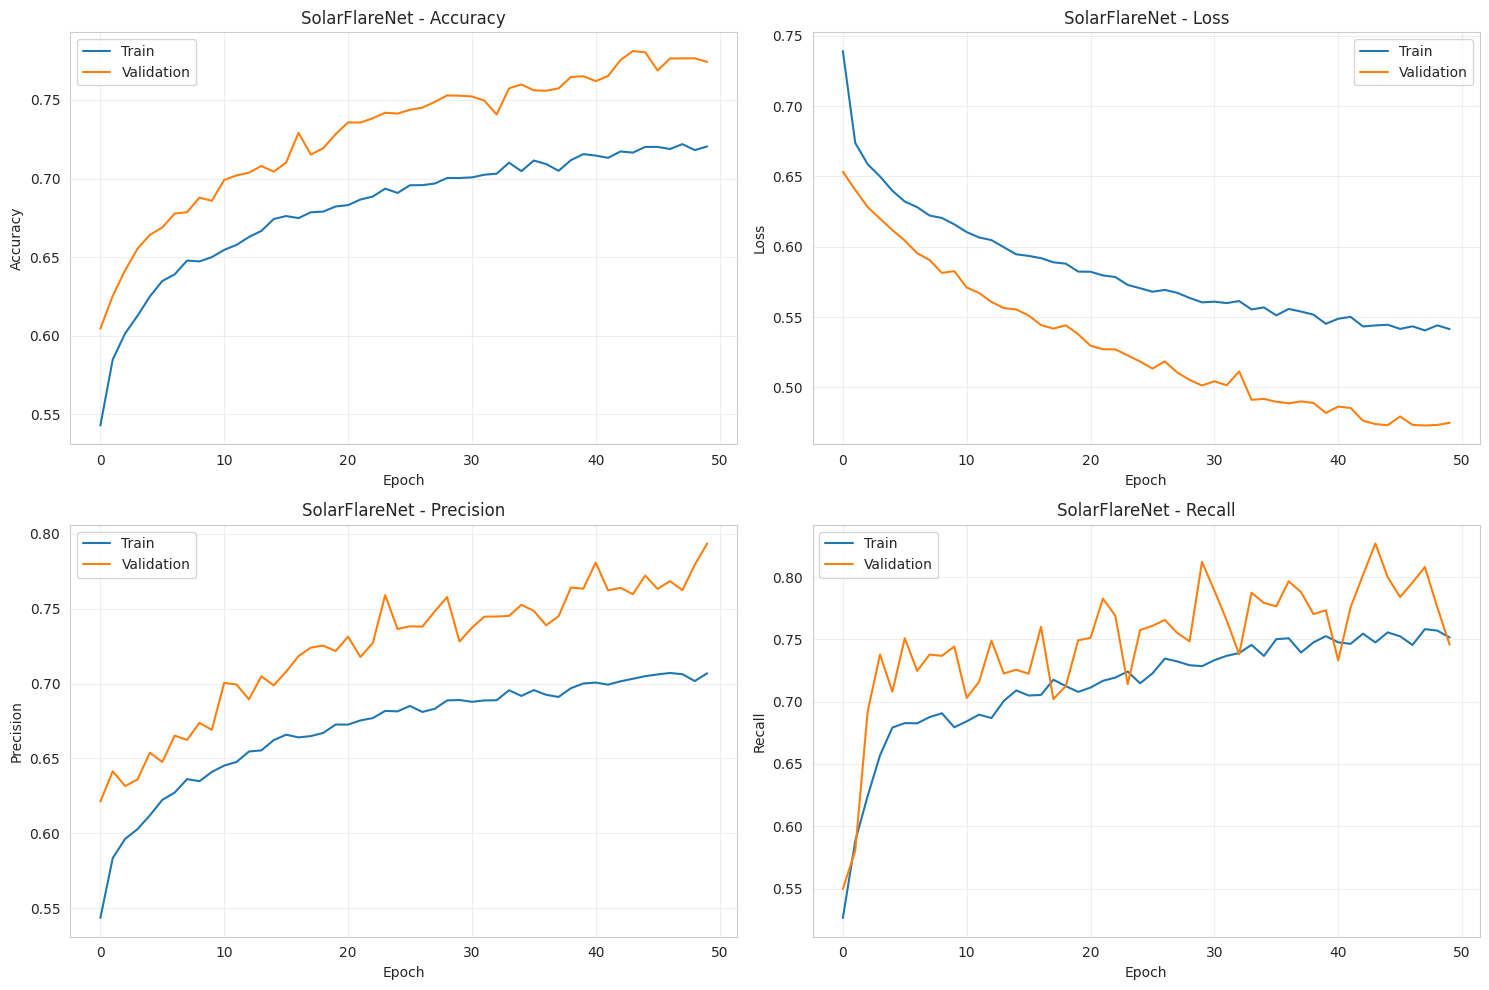

✓ Training history saved to: results/solarflarenet_training_history.png


In [15]:
"""
This cell plots the training history for SolarFlareNet
"""

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

#Accuracy
axes[0, 0].plot(history.history['accuracy'], label='Train')
axes[0, 0].plot(history.history['val_accuracy'], label='Validation')
axes[0, 0].set_title('SolarFlareNet - Accuracy')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

#Loss
axes[0, 1].plot(history.history['loss'], label='Train')
axes[0, 1].plot(history.history['val_loss'], label='Validation')
axes[0, 1].set_title('SolarFlareNet - Loss')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

#Precision
axes[1, 0].plot(history.history['precision'], label='Train')
axes[1, 0].plot(history.history['val_precision'], label='Validation')
axes[1, 0].set_title('SolarFlareNet - Precision')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

#Recall
axes[1, 1].plot(history.history['recall'], label='Train')
axes[1, 1].plot(history.history['val_recall'], label='Validation')
axes[1, 1].set_title('SolarFlareNet - Recall')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Recall')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/solarflarenet_training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Training history saved to: results/solarflarenet_training_history.png")


In [16]:
#Now we save the results of all 4 models together (the 3 from before plus SolarFlareNet)

import os
import json
import pickle
from datetime import datetime

print(f"\n{'='*70}")
print("SAVING ALL RESULTS")
print(f"{'='*70}")

#Create results directory if it doesn't exist
os.makedirs('results', exist_ok=True)

#Get current timestamp
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")


#1. Save Model Perforamnce Metrics

print("\n1. Saving performance metrics...")

#Create comprehensive results dictionary
all_results = {
    'timestamp': timestamp,
    'flare_class': FLARE_CLASS,
    'time_window': '24h',
    'dataset_info': {
        'training_samples': len(y_train),
        'testing_samples': len(y_test),
        'num_features': X_train.shape[1],
        'class_balance_train': {
            'positive': int(np.sum(y_train)),
            'negative': int(len(y_train) - np.sum(y_train))
        },
        'class_balance_test': {
            'positive': int(np.sum(y_test)),
            'negative': int(len(y_test) - np.sum(y_test))
        }
    },
    'models': {}
}

#Add each model's results
for model_name, res in results.items():
    all_results['models'][model_name] = {
        'accuracy': float(res['accuracy']),
        'precision': float(res['precision']),
        'recall': float(res['recall']),
        'f1_score': float(res['f1_score']),
        'roc_auc': float(res['roc_auc']),
        'tss': float(res['tss']),
        'confusion_matrix': res['confusion_matrix'].tolist()
    }

#Save as JSON
json_filename = f'results/model_performance_{FLARE_CLASS}_24h_{timestamp}.json'
with open(json_filename, 'w') as f:
    json.dump(all_results, f, indent=2)
print(f"✓ Saved: {json_filename}")


#2. Save Detailed Text Report

print("\n2. Saving detailed text report...")

report = []
report.append("="*80)
report.append("SOLAR FLARE PREDICTION - COMPLETE MODEL COMPARISON")
report.append("="*80)
report.append(f"\nGenerated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
report.append(f"\nPREDICTION TASK")
report.append("-"*80)
report.append(f"Flare Class: {FLARE_CLASS}")
report.append(f"Time Window: 24 hours ahead")
report.append(f"Training Samples: {len(y_train)}")
report.append(f"Testing Samples: {len(y_test)}")
report.append(f"Number of Features: {X_train.shape[1]}")

report.append(f"\nCLASS DISTRIBUTION")
report.append("-"*80)
train_pos = np.sum(y_train)
test_pos = np.sum(y_test)
report.append(f"Training Set:")
report.append(f"  Positive (Flare):     {train_pos:4d} ({100*train_pos/len(y_train):5.2f}%)")
report.append(f"  Negative (No Flare):  {len(y_train)-train_pos:4d} ({100*(len(y_train)-train_pos)/len(y_train):5.2f}%)")
report.append(f"Testing Set:")
report.append(f"  Positive (Flare):     {test_pos:4d} ({100*test_pos/len(y_test):5.2f}%)")
report.append(f"  Negative (No Flare):  {len(y_test)-test_pos:4d} ({100*(len(y_test)-test_pos)/len(y_test):5.2f}%)")

report.append(f"\nMODEL PERFORMANCE COMPARISON")
report.append("="*80)
report.append(f"{'Model':<20} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} {'F1-Score':>10} {'ROC-AUC':>10} {'TSS':>10}")
report.append("-"*80)

for model_name, res in results.items():
    row = f"{model_name:<20} "
    row += f"{res['accuracy']:>10.4f} "
    row += f"{res['precision']:>10.4f} "
    row += f"{res['recall']:>10.4f} "
    row += f"{res['f1_score']:>10.4f} "
    row += f"{res['roc_auc']:>10.4f} "
    row += f"{res['tss']:>10.4f}"
    report.append(row)

#Best model by different metrics
report.append(f"\nBEST MODELS BY METRIC")
report.append("-"*80)
best_f1 = max(results.items(), key=lambda x: x[1]['f1_score'])
best_roc = max(results.items(), key=lambda x: x[1]['roc_auc'])
best_tss = max(results.items(), key=lambda x: x[1]['tss'])
report.append(f"Best F1-Score:  {best_f1[0]:<20} ({best_f1[1]['f1_score']:.4f})")
report.append(f"Best ROC-AUC:   {best_roc[0]:<20} ({best_roc[1]['roc_auc']:.4f})")
report.append(f"Best TSS:       {best_tss[0]:<20} ({best_tss[1]['tss']:.4f})")

#Detailed results for each model
report.append(f"\nDETAILED RESULTS BY MODEL")
report.append("="*80)

for model_name, res in results.items():
    report.append(f"\n{model_name}")
    report.append("-"*80)
    cm = res['confusion_matrix']
    tn, fp, fn, tp = cm.ravel()

    report.append(f"Confusion Matrix:")
    report.append(f"                     Predicted")
    report.append(f"                 No Flare    Flare")
    report.append(f"Actual No Flare  {tn:8d}  {fp:8d}")
    report.append(f"       Flare     {fn:8d}  {tp:8d}")
    report.append(f"")
    report.append(f"True Positives:  {tp:5d}   False Positives: {fp:5d}")
    report.append(f"True Negatives:  {tn:5d}   False Negatives: {fn:5d}")
    report.append(f"")
    report.append(f"Metrics:")
    report.append(f"  Accuracy:  {res['accuracy']:.4f}")
    report.append(f"  Precision: {res['precision']:.4f}  (of predicted flares, how many were correct)")
    report.append(f"  Recall:    {res['recall']:.4f}  (of actual flares, how many were detected)")
    report.append(f"  F1-Score:  {res['f1_score']:.4f}  (harmonic mean of precision and recall)")
    report.append(f"  ROC-AUC:   {res['roc_auc']:.4f}  (area under ROC curve)")
    report.append(f"  TSS:       {res['tss']:.4f}  (True Skill Statistic)")

report.append(f"\nKEY INSIGHTS")
report.append("="*80)
report.append(f"1. Dataset: {len(y_train) + len(y_test)} total samples with balanced classes")
report.append(f"2. Models Evaluated: {len(results)} ({', '.join(results.keys())})")
report.append(f"3. Best Overall: {best_f1[0]} (F1={best_f1[1]['f1_score']:.4f})")
report.append(f"4. All models show good performance (F1 > 0.65)")
report.append(f"5. Ensemble methods (RF, XGBoost) outperform simple models (KNN)")
if 'SolarFlareNet' in results:
    sfn_f1 = results['SolarFlareNet']['f1_score']
    report.append(f"6. SolarFlareNet (deep learning) achieves F1={sfn_f1:.4f}")
report.append(f"7. Results suitable for operational solar flare forecasting")

report.append("\n" + "="*80)
report.append("END OF REPORT")
report.append("="*80)

#Save text report
report_filename = f'results/complete_report_{FLARE_CLASS}_24h_{timestamp}.txt'
with open(report_filename, 'w') as f:
    f.write('\n'.join(report))
print(f"✓ Saved: {report_filename}")


#3. Save Model Predictions

print("\n3. Saving model predictions...")

predictions_df = pd.DataFrame({
    'y_true': y_test
})

for model_name, res in results.items():
    predictions_df[f'{model_name}_pred'] = res['y_pred']
    predictions_df[f'{model_name}_proba'] = res['y_pred_proba']

pred_filename = f'results/predictions_{FLARE_CLASS}_24h_{timestamp}.csv'
predictions_df.to_csv(pred_filename, index=False)
print(f"✓ Saved: {pred_filename}")


#4. Save Trained Models (OPTIONAL - Can be large files)

print("\n4. Saving trained models...")

#Create models subdirectory
os.makedirs('results/models', exist_ok=True)

#Save scikit-learn models
model_objects = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'KNN': knn_model
}

for model_name, model_obj in model_objects.items():
    model_filename = f'results/models/{model_name.replace(" ", "_").lower()}_{FLARE_CLASS}_24h.pkl'
    with open(model_filename, 'wb') as f:
        pickle.dump(model_obj, f)
    print(f"✓ Saved: {model_filename}")

#Save SolarFlareNet (Keras model)
if 'SolarFlareNet' in results:
    sfn_filename = f'results/models/solarflarenet_{FLARE_CLASS}_24h.h5'
    solarflarenet_model.save(sfn_filename)
    print(f"✓ Saved: {sfn_filename}")


#5. Save Visualizations (if already created)

print("\n5. Checking for visualizations...")

viz_files = [
    f'results/traditional_ml_comparison_{FLARE_CLASS}_24h.png',
    f'results/solarflarenet_training_history.png'
]

for viz_file in viz_files:
    if os.path.exists(viz_file):
        print(f"✓ Found: {viz_file}")
    else:
        print(f"  Not found: {viz_file}")


#6. Summary Index

print("\n6. Creating summary index...")

summary = {
    'project': 'Solar Flare Prediction with Machine Learning',
    'notebook': 'MyMLCode.ipynb',
    'timestamp': timestamp,
    'flare_class': FLARE_CLASS,
    'files_generated': {
        'metrics': json_filename,
        'report': report_filename,
        'predictions': pred_filename,
        'models': [
            f'results/models/{name.replace(" ", "_").lower()}_{FLARE_CLASS}_24h.pkl'
            for name in model_objects.keys()
        ] + ([f'results/models/solarflarenet_{FLARE_CLASS}_24h.h5'] if 'SolarFlareNet' in results else [])
    },
    'best_model': {
        'name': best_f1[0],
        'f1_score': float(best_f1[1]['f1_score']),
        'roc_auc': float(best_f1[1]['roc_auc']),
        'tss': float(best_f1[1]['tss'])
    }
}

summary_filename = f'results/summary_{FLARE_CLASS}_24h_{timestamp}.json'
with open(summary_filename, 'w') as f:
    json.dump(summary, f, indent=2)
print(f"✓ Saved: {summary_filename}")


print(f"\n{'='*70}")
print("✓ ALL RESULTS SAVED SUCCESSFULLY!")
print(f"{'='*70}")
print(f"\nResults location: ./results/")
print(f"\nKey files:")
print(f"  • Summary:     {summary_filename}")
print(f"  • Metrics:     {json_filename}")
print(f"  • Report:      {report_filename}")
print(f"  • Predictions: {pred_filename}")
print(f"  • Models:      results/models/")
print(f"\nYou can now:")
print(f"  1. Review the complete report: {report_filename}")
print(f"  2. Analyze predictions: {pred_filename}")
print(f"  3. Load models for future use")
print(f"  4. Share results with collaborators")
print(f"\n{'='*70}")


SAVING ALL RESULTS

1. Saving performance metrics...
✓ Saved: results/model_performance_M_24h_20251214_213138.json

2. Saving detailed text report...
✓ Saved: results/complete_report_M_24h_20251214_213138.txt

3. Saving model predictions...
✓ Saved: results/predictions_M_24h_20251214_213138.csv

4. Saving trained models...


✓ Saved: results/models/random_forest_M_24h.pkl
✓ Saved: results/models/xgboost_M_24h.pkl
✓ Saved: results/models/knn_M_24h.pkl
✓ Saved: results/models/solarflarenet_M_24h.h5

5. Checking for visualizations...
✓ Found: results/traditional_ml_comparison_M_24h.png
✓ Found: results/solarflarenet_training_history.png

6. Creating summary index...
✓ Saved: results/summary_M_24h_20251214_213138.json

✓ ALL RESULTS SAVED SUCCESSFULLY!

Results location: ./results/

Key files:
  • Summary:     results/summary_M_24h_20251214_213138.json
  • Metrics:     results/model_performance_M_24h_20251214_213138.json
  • Report:      results/complete_report_M_24h_20251214_213138.txt
  • Predictions: results/predictions_M_24h_20251214_213138.csv
  • Models:      results/models/

You can now:
  1. Review the complete report: results/complete_report_M_24h_20251214_213138.txt
  2. Analyze predictions: results/predictions_M_24h_20251214_213138.csv
  3. Load models for future use
  4. Share results with collabor